In [1]:
# Install RDKit.
%%capture
!pip install rdkit

In [2]:
# Importing Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText
import matplotlib.colors as colors
from mpl_toolkits import mplot3d
from math import sqrt
import warnings
import time

from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split,KFold,cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder,LabelEncoder, MinMaxScaler


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor,ExtraTreesRegressor,BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential
from keras.layers import Dense
from keras.models import load_model


from rdkit import Chem
from rdkit.Chem import Draw, PandasTools
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
# from rdkit import DataStructs
# from rdkit.Chem.rdmolops import PatternFingerprint
import pickle
import os
import random
# import os.path as osp

import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams['savefig.dpi'] = 300
plt.rcParams["savefig.format"] = 'tiff'
warnings.filterwarnings("ignore")

In [3]:
seed = 76
os.environ['PYTHONHASHSEED'] = str(seed)
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

In [4]:
sns.set(style='whitegrid')
sns.set_context("paper", font_scale=1.7)


In [5]:
# Learning Rate Scheduler
def scheduler(epoch, lr):
  if epoch < 160:
    return lr
  else:
    return lr * np.exp(-0.1)

callback = keras.callbacks.LearningRateScheduler(scheduler)



# Neural Network
def Neural_network():
    init = keras.initializers.random_normal()
    model=Sequential()
    model.add(layers.Dense(64,activation='relu',kernel_initializer=init, input_dim= trainX.shape[1]))
    model.add(layers.Dropout(0.1))


    model.add(layers.Dense(64,activation='relu',kernel_initializer=init))
    model.add(layers.Dropout(0.1))

    model.add(layers.Dense(1,kernel_initializer=init,activation = 'linear'))


    optimize=tf.keras.optimizers.Adam()

    model.compile(optimizer=optimize,
                    loss='mse',
                    )
    return model



In [6]:
# Funtion to train the model
def training_model(X_train,Y_train,model):
    history=model.fit(X_train,Y_train,epochs=200,batch_size=32,verbose=0,callbacks=[callback])
    return history

In [7]:
# To print losses
def plots():
    f, ax = plt.subplots(1,1)

    actual_test=np.array(scaler.inverse_transform(testY).reshape(-1,1))
    predicted_test=np.array(scaler.inverse_transform(model.predict(testX).reshape(-1,1)))
    actual=np.array(scaler.inverse_transform(np.array(trainY).reshape(-1,1)))
    predicted=np.array(scaler.inverse_transform(model.predict(np.array(trainX)).reshape(-1,1)))

    plt.rcParams["figure.figsize"] = (6,6)
    plt.rcParams['savefig.dpi'] = 300
    plt.rcParams["savefig.format"] = 'tiff'

    sns.set(style='whitegrid')
    sns.set_context("paper", font_scale=1.7)

    plt.scatter(actual_test,predicted_test, color='purple', label='Test', linewidths=1, edgecolors='black', s=75)
    sns.regplot(x=actual,y=predicted, color='orangered', label='Train', scatter_kws={'s':40, 'alpha':0.5, 'edgecolor':'black'})

    print("Mean absolute error (MAE) - Test:      %f" % mean_absolute_error(actual_test,predicted_test))
    print("Mean squared error (MSE) - Test:       %f" % mean_squared_error(actual_test,predicted_test))
    print("Root mean squared error (RMSE) - Test: %f" % sqrt(mean_squared_error(actual_test,predicted_test)))
    print("R square (R^2):                 %f" % r2_score(actual_test,predicted_test))


    plt.xlabel("Actual")
    plt.ylabel('Predicted')
    anchored_text = AnchoredText("R\u00b2 Score_train  "+str(round(r2_score(actual,predicted),3))+'\n'"R\u00b2 Score_test  "+str(round(r2_score(actual_test,predicted_test),3)), loc=2,prop=dict(size=10))
    ax.add_artist(anchored_text)

    plt.legend(loc = 9, prop={'size': 10})
    plt.tight_layout()
    plt.savefig(str(model)[1:6], bbox_inches='tight')

In [8]:
def defining_model(x):
    if x == 'mlr':
      model = LinearRegression()
    elif x=='adboost':
      model = AdaBoostRegressor(random_state=42)
    elif x=='xtratree':
      model = ExtraTreesRegressor(random_state=42)
    elif x=='bagging':
      model = BaggingRegressor(random_state=42)
    elif x=='pls':
      model = PLSRegression()
    elif x=='rndmfrst':
      model = RandomForestRegressor(random_state=42)
    elif x=='knn':
      model = KNeighborsRegressor()
    elif x=='svr':
      model = SVR()
    else:
      print("wrong selection")
    return model


In [9]:
df = pd.read_excel('data.xlsx')

In [10]:
df.shape

(503, 193)

In [11]:
df.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A1,Methylbenzene,-8.03,c1ccccc1,4.242641,0,0,1.333333,6,0,...,6.019242,0,0,0,0,0,1.68660,0.0,0.0,30.941317
1,A2,Methylbenzene,-8.01,Cc1ccccc1,5.059137,0,0,1.245795,6,0,...,8.025656,0,0,0,0,0,1.99502,0.0,0.0,33.544698


In [12]:
Train, Test = train_test_split(
    df, test_size=0.20, random_state=54)

In [13]:
Train.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
251,A252,Substituted Hetero Six-Membered Ring,-8.16,Nc1ccc([NH3+])cc1,5.875634,0,1,1.240597,6,0,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
299,A300,Monoprotonated Borapyridine,-5.06,b1bc[nH+]cb1,4.242641,0,1,1.333333,6,0,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317


In [14]:
# Combine Train and test sets
DF_raw = pd.concat([Train,Test],ignore_index=True)
DF_data = DF_raw.copy()

In [15]:
DF_data.head(2)

,ID,TYPE,NICS(0),Can SMILES,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,A252,Substituted Hetero Six-Membered Ring,-8.16,Nc1ccc([NH3+])cc1,5.875634,0,1,1.240597,6,0,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
1,A300,Monoprotonated Borapyridine,-5.06,b1bc[nH+]cb1,4.242641,0,1,1.333333,6,0,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317


In [16]:
# Removing Unwanted columns
DF_data=DF_data.drop(['TYPE', 'ID', 'Can SMILES'],axis=1)
DF_data.head(3)
# DF_data = DF_data[['NICS(0)','nB', 'Xch-5d', 'n6HRing', 'n7Ring', 'ATSC3s', 'ETA_beta_ns_d',
#                    'ATSC4v', 'BCUTZ-1l', 'nHRing', 'VSA_EState6', 'bpol', 'TSRW10',
#                    'NaaCH', 'AMID', 'IC0']]

,NICS(0),ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,nHetero,nB,nN,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,-8.16,5.875634,0,1,1.240597,6,0,2,0,2,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
1,-5.06,4.242641,0,1,1.333333,6,0,4,3,1,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317
2,-9.23,5.875634,0,0,1.240597,6,0,2,0,1,...,6.452449,0,0,0,0,0,0.9744,0.0,0.0,35.730685


In [17]:
DF_data.shape

(503, 190)

In [18]:
DF_data.head(2)

,NICS(0),ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,nHetero,nB,nN,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,-8.16,5.875634,0,1,1.240597,6,0,2,0,2,...,7.318863,0,0,0,0,0,0.1422,0.0,0.0,35.730685
1,-5.06,4.242641,0,1,1.333333,6,0,4,3,1,...,6.299621,0,1,1,0,0,-1.4850,0.0,0.0,30.941317


In [56]:
# Scaling the whole DataFrame

scaler = StandardScaler()
scaled_DF = pd.DataFrame(scaler.fit_transform(DF_data.iloc[:,1:]))
scaled_DF.columns = DF_data.iloc[:,1:].columns

scaled_DF['NICS(0)'] = scaler.fit_transform(np.array(DF_data['NICS(0)']).reshape(-1,1))

display(scaled_DF)

,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,nHetero,nB,nN,nO,...,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10,NICS(0)
0,0.190254,-0.221460,1.545155,-0.461752,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,-0.549656,-0.478007,-0.216585,-0.233404,0.206000
1,-0.608198,-0.221460,1.545155,1.284478,0.234756,-0.044632,0.591377,3.879907,-0.141974,-0.378529,...,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-1.630892,-0.478007,-0.216585,-1.152398,0.932012
2,0.190254,-0.221460,-0.566837,-0.461752,0.234756,-0.044632,-0.459728,-0.263603,-0.141974,0.324055,...,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,0.003322,-0.478007,-0.216585,-0.233404,-0.044591
3,-0.953938,-0.221460,-0.566837,0.551872,-0.922915,-0.044632,0.591377,-0.263603,-0.944370,-0.378529,...,-0.089532,0.708235,-0.885325,-0.07746,-0.07746,1.006349,-0.478007,-0.216585,0.778604,-1.077401
4,-0.208972,-0.221460,-0.566837,-0.363873,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-0.203065,-0.478007,-0.216585,-0.652856,0.498747
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
498,-0.208972,-0.221460,-0.566837,-0.363873,0.234756,-0.044632,-0.459728,-0.263603,-0.141974,-0.378529,...,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-1.082699,-0.478007,-0.216585,-0.652856,0.697815
499,0.170481,3.904263,-0.566837,-1.049695,-0.922915,-0.044632,0.065825,-0.263603,-0.944370,1.729222,...,-0.089532,0.708235,-0.885325,-0.07746,-0.07746,-0.881296,-0.478007,-0.216585,2.255901,-0.468488
500,0.977747,-0.221460,1.545155,-1.624160,0.234756,-0.044632,-0.985280,-0.263603,-0.141974,-0.378529,...,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,0.607265,2.346080,-0.216585,0.525010,-0.142953
501,-0.608198,-0.221460,-0.566837,1.284478,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-0.327455,-0.478007,-0.216585,-1.152398,0.875805


In [57]:
DF_target = scaled_DF[['NICS(0)']]
scaled_DF.drop('NICS(0)',axis=1,inplace=True)

display(scaled_DF)
display(DF_target)

,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,nHetero,nB,nN,nO,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,0.190254,-0.221460,1.545155,-0.461752,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.357699,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,-0.549656,-0.478007,-0.216585,-0.233404
1,-0.608198,-0.221460,1.545155,1.284478,0.234756,-0.044632,0.591377,3.879907,-0.141974,-0.378529,...,-0.505356,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-1.630892,-0.478007,-0.216585,-1.152398
2,0.190254,-0.221460,-0.566837,-0.461752,0.234756,-0.044632,-0.459728,-0.263603,-0.141974,0.324055,...,-0.483216,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,0.003322,-0.478007,-0.216585,-0.233404
3,-0.953938,-0.221460,-0.566837,0.551872,-0.922915,-0.044632,0.591377,-0.263603,-0.944370,-0.378529,...,-0.664193,-0.089532,0.708235,-0.885325,-0.07746,-0.07746,1.006349,-0.478007,-0.216585,0.778604
4,-0.208972,-0.221460,-0.566837,-0.363873,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.463399,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-0.203065,-0.478007,-0.216585,-0.652856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
498,-0.208972,-0.221460,-0.566837,-0.363873,0.234756,-0.044632,-0.459728,-0.263603,-0.141974,-0.378529,...,1.848714,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-1.082699,-0.478007,-0.216585,-0.652856
499,0.170481,3.904263,-0.566837,-1.049695,-0.922915,-0.044632,0.065825,-0.263603,-0.944370,1.729222,...,-0.478990,-0.089532,0.708235,-0.885325,-0.07746,-0.07746,-0.881296,-0.478007,-0.216585,2.255901
500,0.977747,-0.221460,1.545155,-1.624160,0.234756,-0.044632,-0.985280,-0.263603,-0.141974,-0.378529,...,0.946998,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,0.607265,2.346080,-0.216585,0.525010
501,-0.608198,-0.221460,-0.566837,1.284478,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.506340,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-0.327455,-0.478007,-0.216585,-1.152398


,NICS(0)
0,0.206000
1,0.932012
2,-0.044591
3,-1.077401
4,0.498747
...,...
498,0.697815
499,-0.468488
500,-0.142953
501,0.875805


In [58]:
trainX = scaled_DF[:len(Train)]
testX = scaled_DF[len(Train):]

trainY = DF_target[:len(Train)]
testY = DF_target[len(Train):]

In [59]:
trainX.shape

(402, 189)

In [60]:
testX.shape

(101, 189)

In [61]:
trainX.head(2)

,ABC,nAcid,nBase,SpMAD_A,nAromAtom,nBridgehead,nHetero,nB,nN,nO,...,bpol,n7Ring,nHRing,n6HRing,n5ARing,nAHRing,SLogP,JGI5,JGI6,TSRW10
0,0.190254,-0.22146,1.545155,-0.461752,0.234756,-0.044632,-0.459728,-0.263603,0.660421,-0.378529,...,-0.357699,-0.089532,-1.387307,-0.885325,-0.07746,-0.07746,-0.549656,-0.478007,-0.216585,-0.233404
1,-0.608198,-0.22146,1.545155,1.284478,0.234756,-0.044632,0.591377,3.879907,-0.141974,-0.378529,...,-0.505356,-0.089532,0.708235,1.111619,-0.07746,-0.07746,-1.630892,-0.478007,-0.216585,-1.152398


## **Model screening with 189 descriptors**

In [62]:
totalX = pd.concat([trainX, testX], axis=0)
totalY = pd.concat([trainY, testY], axis=0)

In [63]:
totalX.shape

(503, 189)

Average validation R2 score after crossvalidation :  -3113.843781785138
Average validation rmse score after crossvalidation :  214.56576338406256


Training Accuracy :  0.8244693755162498
Mean absolute error (MAE) - Test:      3.542856
Mean squared error (MSE) - Test:       91.780968
Root mean squared error (RMSE) - Test: 9.580238
R square (R^2):                 -8.226394


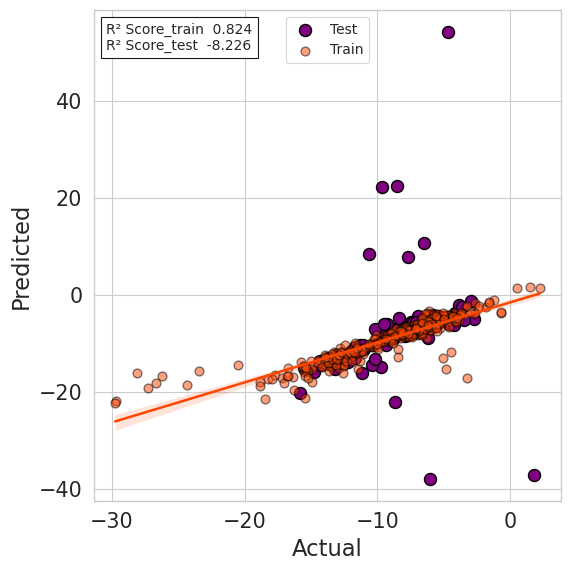

In [ ]:
# Multiple Linear Regression


kfold = KFold(n_splits=5, shuffle=True, random_state=42)
model = defining_model(x = 'mlr')
scores = []
rmse = []
for train,valid in kfold.split(trainX,trainY):
  model.fit(trainX.iloc[train],trainY.iloc[train])
  scores.append(model.score(trainX.iloc[valid],trainY.iloc[valid]))
  actual = trainY.iloc[valid]
  predicted = model.predict(trainX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))
# Unscaled

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

# Train model on whole train data
model = defining_model(x = 'mlr')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

Average validation R2 score after crossvalidation :  0.47015240705503764
Average validation rmse score after crossvalidation :  3.1908763494644274


Training Accuracy :  0.576113751106857
Mean absolute error (MAE) - Test:      1.239980
Mean squared error (MSE) - Test:       3.426549
Root mean squared error (RMSE) - Test: 1.851094
R square (R^2):                 0.655542


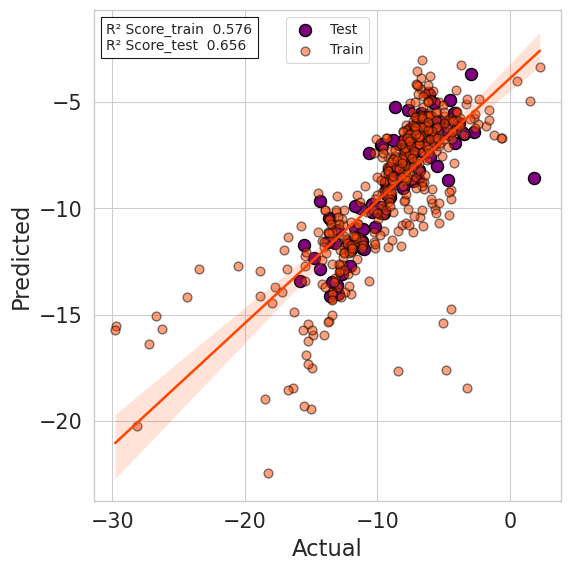

In [ ]:
# Partial Least Square
model = defining_model(x = 'pls')

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(trainX,trainY):
  model.fit(trainX.iloc[train],trainY.iloc[train])
  scores.append(model.score(trainX.iloc[valid],trainY.iloc[valid]))
  actual = trainY.iloc[valid]
  predicted = model.predict(trainX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))
# Unscaled

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

# Train model on whole train data
model = defining_model(x = 'pls')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

Average validation R2 score after crossvalidation :  0.615492152671173
Average validation rmse score after crossvalidation :  2.7368998217607734


Training Accuracy :  0.7951400271545024
Mean absolute error (MAE) - Test:      0.918356
Mean squared error (MSE) - Test:       3.328223
Root mean squared error (RMSE) - Test: 1.824342
R square (R^2):                 0.665426


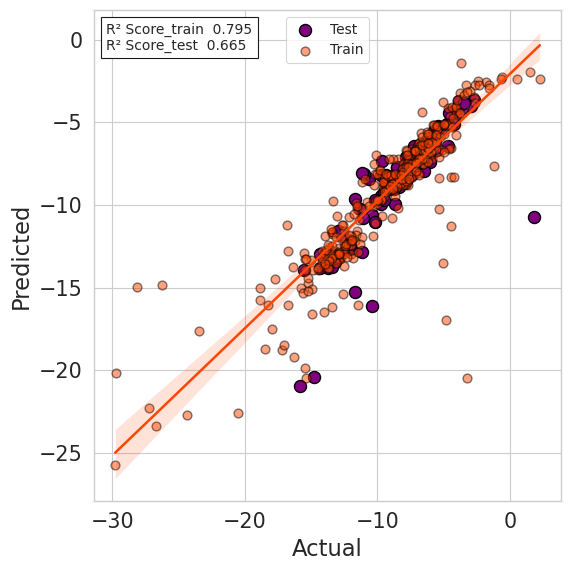

In [ ]:
# KNN
model = defining_model(x = 'knn')

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(trainX,trainY):
  model.fit(trainX.iloc[train],trainY.iloc[train])
  scores.append(model.score(trainX.iloc[valid],trainY.iloc[valid]))
  actual = trainY.iloc[valid]
  predicted = model.predict(trainX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))
# Unscaled

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

# Train model on whole train data
model = defining_model(x = 'knn')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

Average validation R2 score after crossvalidation :  0.6318387508970174
Average validation rmse score after crossvalidation :  2.685927874594803


Training Accuracy :  0.7776098245881362
Mean absolute error (MAE) - Test:      0.755428
Mean squared error (MSE) - Test:       2.271537
Root mean squared error (RMSE) - Test: 1.507162
R square (R^2):                 0.771651


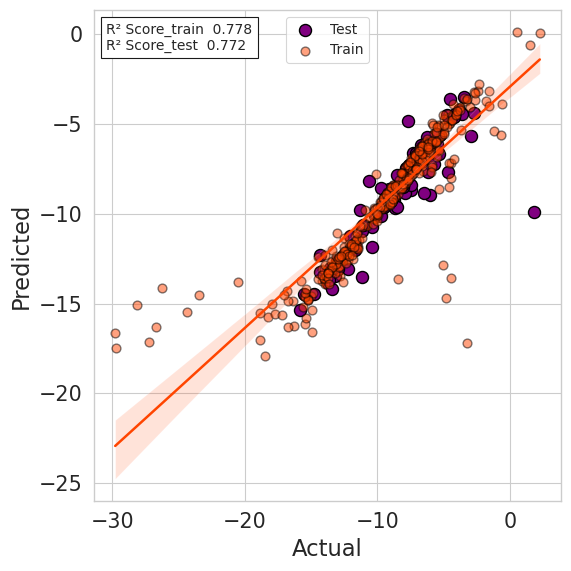

In [ ]:
# Support Vector Regressor
model = defining_model(x = 'svr')

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(trainX,trainY):
  model.fit(trainX.iloc[train],trainY.iloc[train])
  scores.append(model.score(trainX.iloc[valid],trainY.iloc[valid]))
  actual = trainY.iloc[valid]
  predicted = model.predict(trainX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))
# Unscaled

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

# Train model on whole train data
model = defining_model(x = 'svr')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

Average validation R2 score after crossvalidation :  0.6380228258667425
Average validation rmse score after crossvalidation :  2.6134993785512726


Training Accuracy :  0.8310173647445511
Mean absolute error (MAE) - Test:      1.353440
Mean squared error (MSE) - Test:       3.008209
Root mean squared error (RMSE) - Test: 1.734419
R square (R^2):                 0.697596


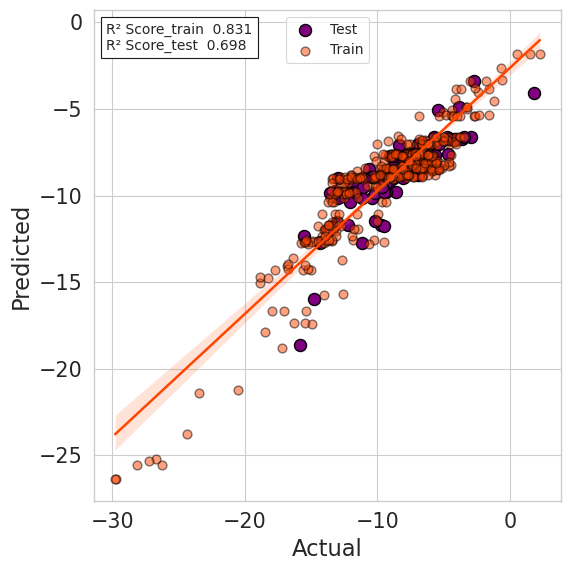

In [ ]:
#Adaboost
model = defining_model(x = 'adboost')
kfold = KFold(n_splits=5, shuffle=True)

scores = []
rmse = []
for train,valid in kfold.split(trainX,trainY):
  model.fit(trainX.iloc[train],trainY.iloc[train])
  scores.append(model.score(trainX.iloc[valid],trainY.iloc[valid]))
  actual = trainY.iloc[valid]
  predicted = model.predict(trainX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))


# Train model on whole train data
model = defining_model(x = 'adboost')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

Average validation R2 score after crossvalidation :  0.8040365106245215
Average validation rmse score after crossvalidation :  1.8684570315803293


Training Accuracy :  0.9998912610942698
Mean absolute error (MAE) - Test:      0.474472
Mean squared error (MSE) - Test:       0.489333
Root mean squared error (RMSE) - Test: 0.699523
R square (R^2):                 0.950809


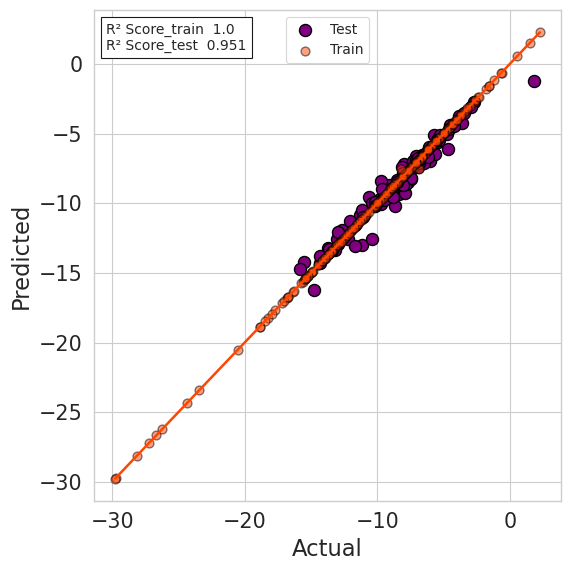

In [ ]:
# Extra Tree Regressor
model = defining_model(x = 'xtratree')
kfold = KFold(n_splits=5, shuffle=True)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model.fit(totalX.iloc[train],totalY.iloc[train])
  scores.append(model.score(totalX.iloc[valid],totalY.iloc[valid]))
  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))


# Train model on whole train data
model = defining_model(x = 'xtratree')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

In [ ]:
# get importance
importance = model.feature_importances_
# summarize feature importance
dicts = {
    'Feature':[x for x in trainX.columns],
    'Importance':importance
    }
DF_imp = pd.DataFrame(dicts)
DF_imp = DF_imp.sort_values('Importance',ascending=False)
DF_imp.to_excel('imp.xlsx', index=None)

# plot feature importance
# plt.bar('Feature','Importance',data = DF_imp.iloc[:10,:])
# plt.xticks(rotation = 90)


In [ ]:
DF_imp.head()

,Feature,Importance
8,nB,0.202254
92,Xch-5d,0.089103
183,n6HRing,0.045599
181,n7Ring,0.026649
134,ETA_beta_ns_d,0.025612


Average validation R2 score after crossvalidation :  0.754383025084757
Average validation rmse score after crossvalidation :  2.0788035450082023


Training Accuracy :  0.9588040796105232
Mean absolute error (MAE) - Test:      0.607733
Mean squared error (MSE) - Test:       0.863542
Root mean squared error (RMSE) - Test: 0.929270
R square (R^2):                 0.913191


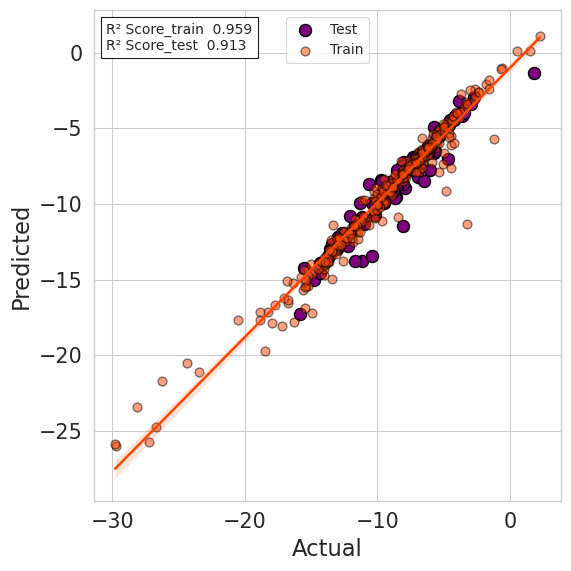

In [ ]:
# Random Forest
model = defining_model(x = 'rndmfrst')
kfold = KFold(n_splits=5, shuffle=True)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model.fit(totalX.iloc[train],totalY.iloc[train])
  scores.append(model.score(totalX.iloc[valid],totalY.iloc[valid]))
  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))


# Train model on whole train data
model = defining_model(x = 'rndmfrst')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

In [ ]:
trainX.shape

(402, 15)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


Training Accuracy :  0.9324172461676915
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Mean absolute error (MAE) - Test:      0.794313
Mean squared error (MSE) - Test:       1.389848
Root mean squared error (RMSE) - Test: 1.178918
R square (R^2):                 0.860284


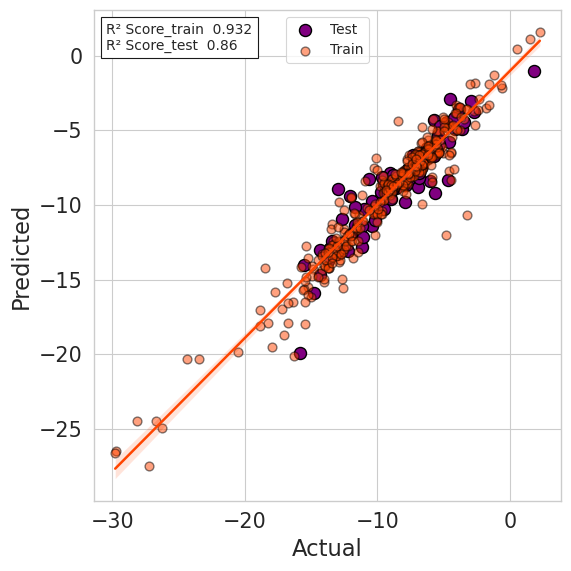

In [ ]:
model = Neural_network()

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model = Neural_network()
  training_model(totalX.iloc[train],totalY.iloc[train],model)
  scores.append(r2_score(totalY.iloc[valid],model.predict(totalX.iloc[valid])))

  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))

# print("Average validation R2 score after crossvalidation : ", np.mean(scores))
# print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

# # Train model on whole train data
tf.keras.backend.clear_session()
model = Neural_network()
training_model(trainX,trainY,model)
#actual = trainY
#predicted = model.predict(trainX)

actual=np.array(scaler.inverse_transform(np.array(trainY)))
predicted=np.array(scaler.inverse_transform(model.predict(np.array(trainX)).reshape(-1,1)))
# model.save("nn.h5")
model.save('nn.keras')
score = r2_score(actual,predicted)
print("\n\nTraining Accuracy : ",score) # Training Accuracy
plots()

In [64]:
# model.summary()

## **Model development using 15 descriptors**

In [19]:
DF_data = DF_raw[['NICS(0)','nB', 'Xch-5d', 'n6HRing', 'n7Ring', 'ATSC3s', 'ETA_beta_ns_d',
                   'ATSC4v', 'BCUTZ-1l', 'nHRing', 'VSA_EState6', 'bpol', 'TSRW10',
                   'NaaCH', 'AMID', 'IC0']]

In [21]:
DF_data.shape

(503, 16)

In [20]:
DF_data.head(2)

,NICS(0),nB,Xch-5d,n6HRing,n7Ring,ATSC3s,ETA_beta_ns_d,ATSC4v,BCUTZ-1l,nHRing,VSA_EState6,bpol,TSRW10,NaaCH,AMID,IC0
0,-8.16,0,0.0,0,0,-3.270281,1.0,-301.460858,5.697914,0,7.439815,7.318863,35.730685,4,1.941604,1.379280
1,-5.06,3,0.0,1,0,-0.111111,0.0,-278.489944,4.778874,1,0.000000,6.299621,30.941317,2,1.968750,1.891061


In [22]:
scaler = StandardScaler()
scaled_DF = pd.DataFrame(scaler.fit_transform(DF_data.iloc[:,1:]))
scaled_DF.columns = DF_data.iloc[:,1:].columns

scaled_DF['NICS(0)'] = scaler.fit_transform(np.array(DF_data['NICS(0)']).reshape(-1,1))

DF_target = scaled_DF[['NICS(0)']]
scaled_DF.drop('NICS(0)',axis=1,inplace=True)

trainX = scaled_DF[:len(Train)]
testX = scaled_DF[len(Train):]

trainY = DF_target[:len(Train)]
testY = DF_target[len(Train):]

totalX = pd.concat([trainX, testX], axis=0)
totalY = pd.concat([trainY, testY], axis=0)

In [23]:
print(trainX.shape, testX.shape, trainY.shape, testY.shape)

(402, 15) (101, 15) (402, 1) (101, 1)


Average validation R2 score after crossvalidation :  0.7973617947668427
Average validation rmse score after crossvalidation :  1.887167515391288


Training Accuracy :  0.9998912610942698
Mean absolute error (MAE) - Test:      0.705799
Mean squared error (MSE) - Test:       1.026549
Root mean squared error (RMSE) - Test: 1.013188
R square (R^2):                 0.896805


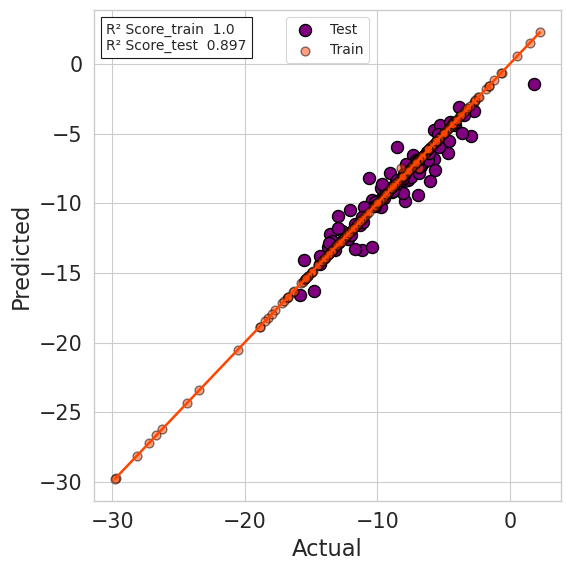

In [82]:
# Extra Tree Regressor
model = defining_model(x = 'xtratree')
kfold = KFold(n_splits=5, shuffle=True)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model.fit(totalX.iloc[train],totalY.iloc[train])
  scores.append(model.score(totalX.iloc[valid],totalY.iloc[valid]))
  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))


# Train model on whole train data
model = defining_model(x = 'xtratree')
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()

In [24]:
# cross-validation with 15 descriptors
model = Neural_network()

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model = Neural_network()
  training_model(totalX.iloc[train],totalY.iloc[train],model)
  scores.append(r2_score(totalY.iloc[valid],model.predict(totalX.iloc[valid])))

  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Average validation R2 score after crossvalidation :  0.7300902724266052
Average validation rmse score after crossvalidation :  2.172624071870675


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


Training Accuracy :  0.9278208097275051
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Mean absolute error (MAE) - Test:      0.795294
Mean squared error (MSE) - Test:       1.314480
Root mean squared error (RMSE) - Test: 1.146508
R square (R^2):                 0.867860


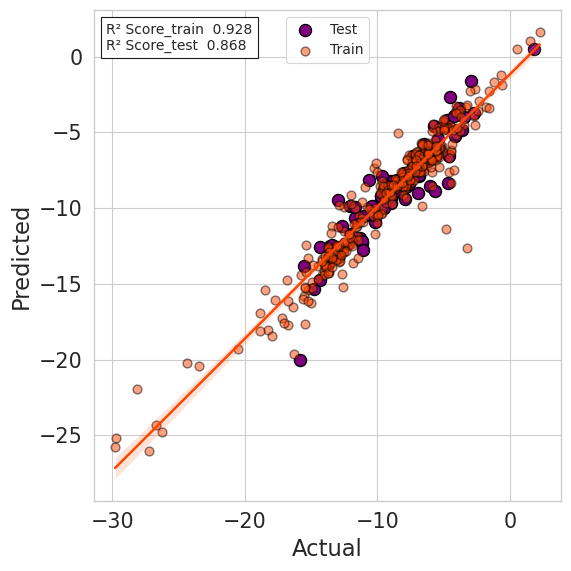

In [25]:
# Train model on whole train data
tf.keras.backend.clear_session()
model = Neural_network()
training_model(trainX,trainY,model)

actual=np.array(scaler.inverse_transform(np.array(trainY)))
predicted=np.array(scaler.inverse_transform(model.predict(np.array(trainX)).reshape(-1,1)))

score = r2_score(actual,predicted)
print("\n\nTraining Accuracy : ",score) # Training Accuracy
plots()

## **Hyperparameter Tuning for ET model**

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Base model
et = ExtraTreesRegressor(random_state=42)

# Parameter space
param_dist = {
    'n_estimators': randint(200, 1000),
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', None, 0.5, 0.7],
    'bootstrap': [False, True]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=et,
    param_distributions=param_dist,
    n_iter=100,
    scoring='r2',
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Fit
random_search.fit(trainX, trainY)

# Best model
best_et = random_search.best_estimator_

# Evaluate
train_r2 = best_et.score(trainX, trainY)
test_r2 = best_et.score(testX, testY)

print("Best Parameters:", random_search.best_params_)
print("Train R2:", train_r2)
print("Test R2:", test_r2)

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Parameters: {'bootstrap': False, 'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 883}
Train R2: 0.9502478020804862
Test R2: 0.8966909889809341


Average validation R2 score after crossvalidation :  0.7852989456471677
Average validation rmse score after crossvalidation :  1.9319995152310525


Training Accuracy :  0.9498613629396874
Mean absolute error (MAE) - Test:      0.701073
Mean squared error (MSE) - Test:       1.050405
Root mean squared error (RMSE) - Test: 1.024893
R square (R^2):                 0.894407


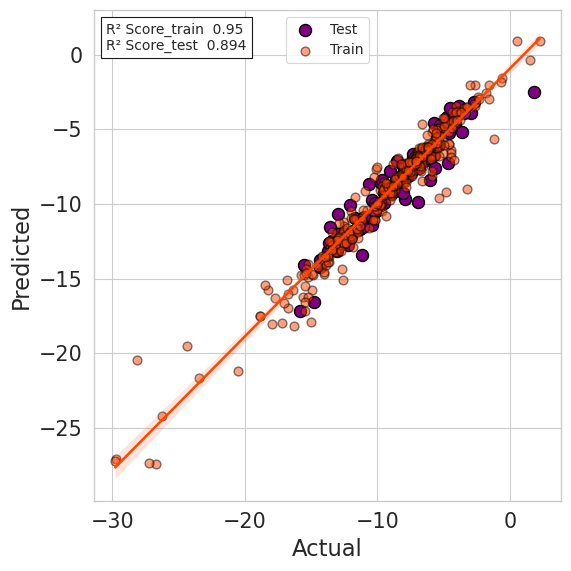

In [ ]:
# Extra Tree Regressor


kfold = KFold(n_splits=5, shuffle=True)

scores = []
rmse = []
for train,valid in kfold.split(totalX,totalY):
  model = ExtraTreesRegressor(n_estimators=883, max_depth=None,
                            min_samples_split=6,bootstrap  = False,
                            max_features=None, min_samples_leaf = 2)
  model.fit(totalX.iloc[train],totalY.iloc[train])
  scores.append(model.score(totalX.iloc[valid],totalY.iloc[valid]))
  actual = totalY.iloc[valid]
  predicted = model.predict(totalX.iloc[valid])
  rmse.append(sqrt(mean_squared_error(scaler.inverse_transform(actual),scaler.inverse_transform(predicted.reshape(-1,1)))))

print("Average validation R2 score after crossvalidation : ", np.mean(scores))
print("Average validation rmse score after crossvalidation : ", np.mean(rmse))


# Train model on whole train data
model = ExtraTreesRegressor(n_estimators=883, max_depth=None,
                            min_samples_split=6,bootstrap  = False,
                            max_features=None, min_samples_leaf = 2)
model.fit(trainX,trainY)
print("\n\nTraining Accuracy : ",model.score(trainX,trainY)) # Training Accuracy
plots()